Joonseo Bang & Myles Lewis

Background information : According to the dataset, it shows the record of geometric properties and values of kernels of three different varieties of kama, rosa, and canadian(70 elements each with random selection for fair experiment). In this colab, we are going to explore the characteristics of these seeds and by using the PCA, we will figure out the way to reduce dimensionality, variance retention and finally, the visualization of the effectiveness of geometric characteristics in sorting and the difference of wheat.

Data source link : https://archive.ics.uci.edu/dataset/236/seeds

In [ ]:
import numpy as np                          # For numerical operations
import pandas as pd                         # For loading and managing the dataset
import matplotlib.pyplot as plt             # For plotting the PCA scatter chart

from sklearn.preprocessing import StandardScaler   # For normalizing feature values
from sklearn.decomposition import PCA              # For reducing dimensions via PCA

print('All libraries imported successfully!')

All libraries imported successfully!


In [ ]:
seeds_dataset = pd.read_csv('seeds_dataset.txt', sep='\s+', header=None)
seeds_dataset.columns = [
    'area', 'perimeter', 'compactness', 'length',
    'width', 'asymmetry_coefficient', 'groove_length', 'target'
]

print('Dataset shape:', seeds_dataset.shape)
seeds_dataset.head()

Dataset shape: (210, 8)


<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:1: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_895/586142825.py:1: SyntaxWarning: invalid escape sequence '\s'
  seeds_dataset = pd.read_csv('seeds_dataset.txt', sep='\s+', header=None)


,area,perimeter,compactness,length,width,asymmetry_coefficient,groove_length,target
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


The step of brining dataset with column names from the data source link, such as area, perimeter, compactness, length, width, asymmetry coefficient, groove length, and target.

In [ ]:
seeds_dataset

,area,perimeter,compactness,length,width,asymmetry_coefficient,groove_length,target
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1
...,...,...,...,...,...,...,...,...
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3


According to the dataset, it shows 210 rows and 8 columns in total.

In [ ]:
features = [col for col in seeds_dataset.columns if col != 'target']

X = seeds_dataset[features]
y = seeds_dataset['target']

print('Number of features:', len(features))
print('Target distribution:')
print(y.value_counts().sort_index())

Number of features: 7
Target distribution:
target
1    70
2    70
3    70
Name: count, dtype: int64


Just as we excluded 'Wine_type' in the example, we designate the remaining 7 columns—excluding the final column, 'target'—as features (X).

In [ ]:
x_scaled = StandardScaler().fit_transform(X)

print('Normalized data Mean:', np.mean(x_scaled))
print('Normalized data Std:', np.std(x_scaled))

Normalized data Mean: -2.6584932290343884e-16
Normalized data Std: 1.0


As explained in the example, standardization is essential because the variables have different units and ranges (such as area, length, etc.).

In [ ]:
pca = PCA(n_components=2)
principal_components = pca.fit_transform(x_scaled)

pca_df = pd.DataFrame(principal_components, columns=['PC1', 'PC2'])

pc1_var, pc2_var = pca.explained_variance_ratio_
print(f'PC1 Variance: {pc1_var:.1%}')
print(f'PC2 Variance: {pc2_var:.1%}')
print(f'Total 2D Variance Retained: {pc1_var + pc2_var:.1%}')

PC1 Variance: 71.9%
PC2 Variance: 17.1%
Total 2D Variance Retained: 89.0%


The process of making the dataset as 2D shape, and at the same time, explained variance ratio.

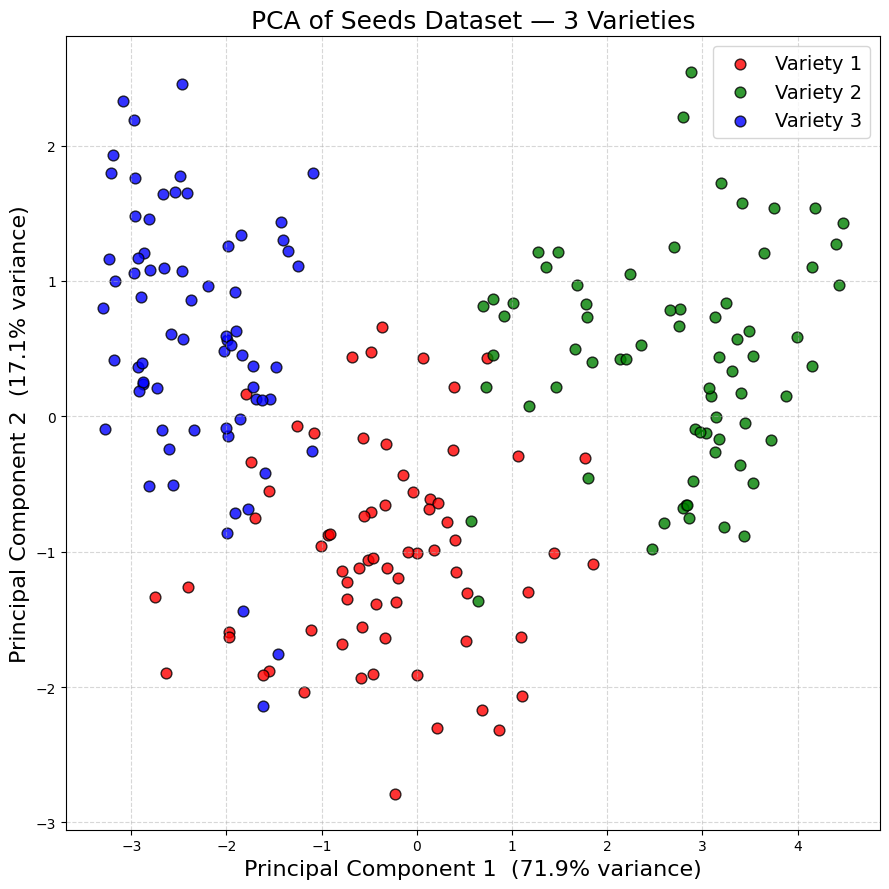

In [ ]:
plt.figure(figsize=(9, 9))
plt.xlabel('Principal Component 1  ({:.1%} variance)'.format(pc1_var), fontsize=16)
plt.ylabel('Principal Component 2  ({:.1%} variance)'.format(pc2_var), fontsize=16)
plt.title('PCA of Seeds Dataset — 3 Varieties', fontsize=18)

# For each one like Kama, Rose, Canadian, put the color for each
colors = {
    1: ('r', 'Variety 1'),
    2: ('g', 'Variety 2'),
    3: ('b', 'Variety 3')
}

for label, (color, name) in colors.items():
    mask = y == label
    plt.scatter(
        pca_df.loc[mask, 'PC1'],
        pca_df.loc[mask, 'PC2'],
        c=color, s=60, label=name, edgecolor='k', alpha=0.8
    )

plt.legend(prop={'size': 14})
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('pca_seeds.png', dpi=150)
plt.show()

Above scatter plot of PCA of Seeds dataset with 3 varieties are the visualization of clustering with 3 varieties.

In conclusion, through the step-by-step, we were successfully able to apply PCA to the Seeds dataset to explore the geometric characteristics of three wheat features such as Kama, Rosa, and Canadian.


For the PCA with n_components as 2, it standardized a dataset with 7 features and made it into 2 principal components. Eventually, we could get total 2D variance retained: 89.0%.



The above scatter plot of PCA of Seeds Dataset with 3 varieties explains the unique geometric characteristics of seeds well. Although there are a few outliers, the overall separation between the clustering shows the geometric features are really effective for distinguishing and classifying the seeds depending on their wheat features such as Kama, Rosa, and Canadian.



Lastly, during the process of using PCA for simplifying vast seeds dataset, it showed the powerful effect and proved that PCA is a key role for preserving the variability for biological classification.